# این بلوک کد برای راه‌اندازی و احراز هویت کتابخانه Earth Engine و همچنین اتصال Google Drive به محیط Colab استفاده می‌شود.


In [5]:
# راه‌اندازی Earth Engine
import ee
ee.Authenticate()
ee.Initialize(project='pars-460214')

# وارد کردن کتابخانه‌های مورد نیاز
import geopandas as gpd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


این کد یک **اسکریپت پایتون** جامع برای **نظارت بر تالاب شادگان** با استفاده از داده‌های ماهواره‌ای **لندست (Landsat)** در پلتفرم **Google Earth Engine (GEE)** است. هدف اصلی این اسکریپت، **تجزیه و تحلیل تغییرات زمانی در پوشش گیاهی، آب و کدورت (غلظت رسوبات معلق)** تالاب در طول سالیان مشخص است.

---

## سال‌های مورد تحلیل

این اسکریپت داده‌ها را برای سال‌های **2015 تا 2025** (شامل هر دو سال) و به طور خاص برای **ماه جولای (ماه 7)** هر سال پردازش می‌کند.

---

## فرمول‌های استفاده شده

این اسکریپت از سه شاخص ماهواره‌ای اصلی استفاده می‌کند که هر کدام با استفاده از باندهای مختلف طیفی تصاویر لندست محاسبه می‌شوند:

* **شاخص نرمال شده پوشش گیاهی (NDVI - Normalized Difference Vegetation Index)**:
    این شاخص برای ارزیابی سلامت و تراکم پوشش گیاهی استفاده می‌شود. مقادیر بالاتر NDVI نشان‌دهنده پوشش گیاهی متراکم‌تر و سالم‌تر است.
    
    $$NDVI = (NIR - Red) / (NIR + Red)$$

    که در آن:
    * **NIR**: باند فروسرخ نزدیک (Near-Infrared) (SR_B5 در لندست 8/9)
    * **Red**: باند قرمز (SR_B4 در لندست 8/9)

* **شاخص نرمال شده آب (NDWI - Normalized Difference Water Index)**:
    این شاخص برای شناسایی و نقشه‌برداری از پهنه‌های آبی استفاده می‌شود. مقادیر بالاتر NDWI نشان‌دهنده حضور آب است.
    
    $$NDWI = (Green - NIR) / (Green + NIR)$$

    که در آن:
    * **Green**: باند سبز (SR_B3 در لندست 8/9)
    * **NIR**: باند فروسرخ نزدیک (SR_B5 در لندست 8/9)

* **شاخص نرمال شده کدورت (NDTI - Normalized Difference Turbidity Index)**:
    این شاخص می‌تواند برای تخمین کدورت یا غلظت رسوبات معلق در آب استفاده شود. در این مورد خاص، فرمول استفاده شده شبیه به شاخص نرمال شده کدورت است و به عنوان "Turbidity (NDTI)" در خروجی‌ها برچسب‌گذاری می‌شود.
    
    $$NDTI = (Red - Green) / (Red + Green)$$

    که در آن:
    * **Red**: باند قرمز (SR_B4 در لندست 8/9)
    * **Green**: باند سبز (SR_B3 در لندست 8/9)

---

## توابع اصلی

* `handle_errors(func)`: یک تابع دکوراتور برای مدیریت خطاها در توابع GEE و Python است. این تابع تلاش می‌کند تا خطاهای GEE را شناسایی کرده و گزارش دهد و در صورت بروز خطا، مقدار `None` را بازگرداند.
* `get_aoi()`: ناحیه مورد علاقه (Area of Interest - AOI) را از Google Earth Engine به عنوان یک FeatureCollection بارگذاری کرده و هندسه آن را بازمی‌گرداند.
* `save_image_with_legend(ee_image, band_name, vis_params, year, month, output_dir, index_label, region_bounds_for_url)`: تصاویر JPEG از شاخص‌های محاسبه شده را به همراه یک مقیاس رنگ (legend) بصورت محلی ذخیره می‌کند.
* `start_tiff_export_to_drive(ee_image, year, month, aoi_geometry_for_export, drive_folder)`: یک کار (task) برای استخراج تصاویر TIFF چند باندی (شامل NDVI, NDWI, NDTI) به پوشه مشخصی در Google Drive آغاز می‌کند. این خروجی‌ها برای تجزیه و تحلیل‌های GIS پیشرفته‌تر مفید هستند.
* `get_landsat_data_and_image(year, month, aoi_geometry)`:
    * تصاویر لندست 8 و 9 (سطح 2) را برای ماه و سال مشخص فیلتر می‌کند.
    * توابع داخلی برای **مقیاس‌بندی باندها (`scale_bands`)** و **ماسک کردن ابرها (`cloud_mask_landsat`)** را اعمال می‌کند تا داده‌های قابل اطمینان‌تری بدست آید.
    * **شاخص‌های NDVI، NDWI و NDTI** را برای هر تصویر محاسبه می‌کند.
    * یک تصویر **مدیان (Median image)** از تمام تصاویر پردازش شده در دوره زمانی مشخص ایجاد می‌کند.
    * **میانگین آماری** هر شاخص را در کل AOI محاسبه می‌کند.
    * **مساحت پوشش گیاهی و آب** را بر حسب کیلومتر مربع، با استفاده از آستانه‌های تعریف شده، محاسبه می‌کند.
    * تصویر مدیان و داده‌های آماری را بازمی‌گرداند.
* `create_gif(image_files, output_gif_path, duration=0.8)`: از مجموعه تصاویر JPEG تولید شده، یک فایل GIF متحرک ایجاد می‌کند تا تغییرات سالانه را بصورت بصری نمایش دهد.
* `main()`: تابع اصلی که کل جریان پردازش را هماهنگ می‌کند. این تابع بر روی سال‌های مشخص شده تکرار می‌شود، داده‌های لندست را بازیابی و پردازش می‌کند، آمارها را جمع‌آوری می‌کند، تصاویر JPEG (برای سال‌های انتخابی) و فایل‌های TIFF (برای سال‌های 2015 و 2024) را تولید می‌کند. همچنین، نتایج را در یک فایل CSV ذخیره کرده و نمودارهای تعاملی Plotly و فایل‌های GIF را برای تجسم روندها ایجاد می‌کند.

---

## خروجی‌ها

این اسکریپت چندین نوع خروجی تولید می‌کند که همگی در پوشه `shadegan_analysis_results` (قابل تنظیم با `OUTPUT_DIR`) ذخیره می‌شوند:

* **تصاویر JPEG با مقیاس رنگ (Legend)**:
    * برای هر سالی که در `YEARS` تعیین شده و **سال 2015 یا 2024 نباشد**، تصاویر JPEG جداگانه برای **NDVI، NDWI و NDTI** تولید می‌شود. این تصاویر تغییرات مکانی شاخص‌ها را در طول زمان به صورت بصری نشان می‌دهند.
    * نامگذاری فایل‌ها به صورت `[IndexName]_[Year]_[Month].jpg` (مثال: `NDVI_2016_07.jpg`).

* **فایل‌های GeoTIFF (به Google Drive)**:
    * برای سال‌های **2015 و 2024**، تصاویر چند باندی حاوی NDVI، NDWI و NDTI به صورت فایل‌های GeoTIFF به پوشه‌ای در Google Drive (که با `DRIVE_EXPORT_FOLDER` مشخص می‌شود) خروجی داده می‌شوند. این فایل‌ها برای تجزیه و تحلیل‌های مکانی و GIS پیشرفته‌تر مناسب هستند.
    * نامگذاری فایل‌ها به صورت `Indices_Multiband_[Year]_[Month].tiff` (مثال: `Indices_Multiband_2015_07.tiff`).

* **فایل CSV از نتایج سالانه**:
    * یک فایل `annual_indices_results.csv` حاوی میانگین سالانه NDVI، NDWI، NDTI و همچنین مساحت پوشش گیاهی و آب (بر حسب کیلومتر مربع) برای هر سال پردازش شده تولید می‌شود. این فایل برای تجزیه و تحلیل‌های آماری و کمی مفید است.

* **فایل‌های GIF متحرک**:
    * سه فایل GIF (در صورت تولید تصاویر JPEG مربوطه) ایجاد می‌شود که تغییرات سالانه هر شاخص را در طول دوره زمانی به صورت انیمیشن نمایش می‌دهند:
        * `ndvi_annual_changes.gif`
        * `ndwi_annual_changes.gif`
        * `ndti_turbidity_annual_changes.gif`

* **نمودار تعاملی Plotly (HTML)**:
    * یک فایل `interactive_plot.html` حاوی یک نمودار تعاملی تولید می‌شود که روند تغییرات میانگین NDVI، NDWI، NDTI و همچنین مساحت پوشش گیاهی و آب را در طول سالیان نشان می‌دهد. این نمودار به کاربر امکان می‌دهد تا با داده‌ها تعامل داشته باشد (بزرگنمایی، اطلاعات نقطه داده‌ها و غیره).

* **فایل لاگ (Log File)**:
    * تمامی اطلاعات مربوط به پردازش، هشدارها و خطاها در فایل `analysis.log` در پوشه خروجی ثبت می‌شوند، که برای اشکال‌زدایی و نظارت بر اجرای اسکریپت مفید است.

---

In [9]:
import ee
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import requests
from io import BytesIO
import time
import os
import logging
import matplotlib.pyplot as plt
import matplotlib.colors
from PIL import Image
import imageio
import datetime
import shutil

# Configuration
PROJECT_ID = 'pars-460214' # لطفا شناسه پروژه خود را وارد کنید
SHADEGAN_AOI_ASSET_ID = "projects/pars-460214/assets/dom"
NDVI_THRESHOLD = 0.25
NDWI_THRESHOLD = 0.1
OUTPUT_DIR = 'shadegan_analysis_results'
YEARS = list(range(2015, 2026))
MONTH = 7
DRIVE_EXPORT_FOLDER = 'Shadegan_Analysis_TIFFs'

# --- Visualization Parameters ---
NDVI_VIS_PARAMS = {'min': -0.2, 'max': 0.8, 'palette': ['#8B4513', '#FFFACD', '#006400']}
NDWI_VIS_PARAMS = {'min': -0.5, 'max': 0.8, 'palette': ['#FFBF00', '#FFFFFF', '#0000FF']}
TURBIDITY_VIS_PARAMS = {'min': -0.3, 'max': 0.5, 'palette': ['#000080', '#ADD8E6', '#FFFF00', '#FFA500', '#A52A2A']}

os.makedirs(OUTPUT_DIR, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    handlers=[
        logging.FileHandler(os.path.join(OUTPUT_DIR, 'analysis.log')),
        logging.StreamHandler()
    ]
)

try:
    ee.Initialize(project=PROJECT_ID)
    logging.info("GEE initialized successfully")
except Exception as e:
    logging.error(f"GEE initialization failed: {str(e)}")
    raise

def handle_errors(func):
    def wrapper(*args, **kwargs):
        try:
            return func(*args, **kwargs)
        except ee.EEException as gee_error:
            logging.error(f"GEE Error in {func.__name__}: {str(gee_error)}")

            return None
        except Exception as e:
            logging.error(f"Non-GEE Error in {func.__name__}: {str(e)}")
            return None
    return wrapper

@handle_errors
def get_aoi():
    aoi_fc = ee.FeatureCollection(SHADEGAN_AOI_ASSET_ID)
    if aoi_fc.size().getInfo() == 0:
        raise ValueError("AOI is empty or could not be loaded.")
    return aoi_fc.geometry()

AOI_GEOMETRY = get_aoi()
AOI_BOUNDS = None
if AOI_GEOMETRY:
    try:
        AOI_BOUNDS = AOI_GEOMETRY.bounds(maxError=1).getInfo()['coordinates']
    except ee.EEException as e:
        logging.warning(f"Could not get AOI bounds directly: {e}. Trying with simplified geometry.")
        try:
            AOI_BOUNDS = AOI_GEOMETRY.simplify(maxError=100).bounds(maxError=1).getInfo()['coordinates']
        except Exception as e_simple:
            logging.error(f"Could not get simplified AOI bounds: {e_simple}. JPEG/Thumbnail exports might fail or be incorrect.")
else:
    logging.error("AOI Geometry could not be loaded. Exiting.")
    exit()


@handle_errors
def save_image_with_legend(ee_image, band_name, vis_params, year, month, output_dir, index_label, region_bounds_for_url):

    if not region_bounds_for_url:
        logging.warning(f"Region bounds not available for JPEG {band_name} {year}-{month:02d}. Skipping.")
        return None
    filename = os.path.join(output_dir, f'{band_name}_{year}_{month:02d}.jpg')
    logging.info(f"Generating JPEG for {band_name} for {year}-{month:02d}...")

    try:
        img_clipped = ee_image.select(band_name)
        thumb_url = img_clipped.getThumbURL({
            'bands': band_name, 'min': vis_params['min'], 'max': vis_params['max'],
            'palette': vis_params['palette'], 'region': region_bounds_for_url,
            'dimensions': 768, 'format': 'png'
        })
        response = requests.get(thumb_url, timeout=60)
        response.raise_for_status()
        img_data = BytesIO(response.content)
        pil_image = Image.open(img_data)
        img_array = np.array(pil_image)

        fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
        im = ax.imshow(img_array)
        ax.set_title(f'{index_label} - {year}-{month:02d}', fontsize=14)
        ax.axis('off')
        cmap = matplotlib.colors.ListedColormap(vis_params['palette'])
        norm = matplotlib.colors.Normalize(vmin=vis_params['min'], vmax=vis_params['max'])
        cbar = fig.colorbar(matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
        cbar.set_label(f'{index_label} Value', fontsize=12)
        plt.savefig(filename, bbox_inches='tight')
        plt.close(fig)
        logging.info(f"Saved {filename}")
        return filename
    except requests.exceptions.Timeout:
        logging.error(f"Timeout downloading thumbnail for JPEG {band_name} {year}-{month:02d}.")
        return None
    except Exception as e:
        logging.error(f"Failed to generate JPEG for {band_name} {year}-{month:02d}: {e}")
        return None

@handle_errors
def start_tiff_export_to_drive(ee_image, year, month, aoi_geometry_for_export, drive_folder):
    filename_base = f'Indices_Multiband_{year}_{month:02d}'
    task_description = f'Export_TIFF_{filename_base}'

    logging.info(f"Initiating TIFF export to Google Drive for {year}-{month:02d}. Task description: {task_description}")

    try:
        # Ensure bands are float for GeoTIFF compatibility, GEE often handles this but explicit is safer.
        image_to_export = ee_image.select(['NDVI', 'NDWI', 'NDTI']).toFloat()

        task = ee.batch.Export.image.toDrive(
            image=image_to_export,
            description=task_description,
            folder=drive_folder,
            fileNamePrefix=filename_base,
            region=aoi_geometry_for_export,
            scale=30,
            crs='EPSG:4326',
            maxPixels=1e13
        )
        task.start()
        logging.info(f"Task '{task_description}' started for {filename_base}. "
                     f"Check GEE Tasks tab or Google Drive folder '{drive_folder}' (may take time to appear and complete). "
                     f"Task ID: {task.id}")
        return task.id
    except ee.EEException as e:
        logging.error(f"GEE Error starting Drive export for {year}-{month:02d}: {e}")
        raise
    except Exception as e:
        logging.error(f"Non-GEE error starting Drive export for {year}-{month:02d}: {e}")
        raise

@handle_errors
def get_landsat_data_and_image(year, month, aoi_geometry):

    if not aoi_geometry:
        logging.error("AOI geometry is not available for get_landsat_data_and_image.")
        return None, None

    start_date = ee.Date.fromYMD(year, month, 1)
    end_date = start_date.advance(1, 'month')

    try:
        l8 = ee.ImageCollection('LANDSAT/LC08/C02/T1_L2').filterDate(start_date, end_date)
        l9 = ee.ImageCollection('LANDSAT/LC09/C02/T1_L2').filterDate(start_date, end_date)
        collection = l8.merge(l9).filterBounds(aoi_geometry)
        collection_size = collection.size().getInfo()
        if collection_size == 0:
            logging.warning(f"No Landsat images found for {year}-{month} in the AOI.")
            return None, None
    except ee.EEException as e:
        logging.error(f"GEE error during initial collection for {year}-{month}: {e}")
        if "Computation timed out" not in str(e) and "Too many concurrent aggregations" not in str(e):
             return None, None
        raise

    def scale_bands(img):
        optical = img.select('SR_B.').multiply(0.0000275).add(-0.2)
        thermal = img.select('ST_B10').multiply(0.00341802).add(149.0)
        return img.addBands(optical, None, True).addBands(thermal, None, True)

    def cloud_mask_landsat(img):
        qa = img.select('QA_PIXEL')
        dilated_cloud = (qa.rightShift(1)).bitwiseAnd(1)
        cirrus = (qa.rightShift(2)).bitwiseAnd(1)
        cloud = (qa.rightShift(3)).bitwiseAnd(1)
        cloud_shadow = (qa.rightShift(4)).bitwiseAnd(1)
        mask = dilated_cloud.eq(0).And(cirrus.eq(0)).And(cloud.eq(0)).And(cloud_shadow.eq(0))
        return img.updateMask(mask)

    def calculate_indices(img):
        ndvi = img.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI')
        ndwi = img.normalizedDifference(['SR_B3', 'SR_B5']).rename('NDWI')
        ndti = img.normalizedDifference(['SR_B4', 'SR_B3']).rename('NDTI')
        return img.addBands(ndvi).addBands(ndwi).addBands(ndti)

    processed_collection = collection.map(scale_bands).map(cloud_mask_landsat).map(calculate_indices)
    processed_size = processed_collection.size().getInfo()
    if processed_size == 0:
        logging.warning(f"No cloud-free images after processing for {year}-{month}.")
        return None, None

    median_img = processed_collection.median().clip(aoi_geometry)

    try:
        probe_val = median_img.select('NDVI').reduceRegion(ee.Reducer.first(), aoi_geometry.centroid(maxError=1), 30).getInfo()
        if not probe_val or probe_val.get('NDVI') is None:

            logging.warning(f"Median image probe for {year}-{month} returned no NDVI value. Image might be empty or problematic.")
    except ee.EEException as e_probe:
        logging.error(f"Failed to probe median_img for {year}-{month}: {e_probe}. The image computation might be too complex or failing.")
        if "Computation timed out" in str(e_probe) or "memory limit" in str(e_probe).lower() or "capacity" in str(e_probe).lower():
            raise
        return None, None

    stats = median_img.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=aoi_geometry, scale=30,
        maxPixels=1e10, tileScale=4
    ).getInfo()

    def get_pixel_area(image_to_calc_area, band, threshold, geometry_for_reduce):
        try:
            area_image = image_to_calc_area.select(band).gt(threshold)
            area = area_image.multiply(ee.Image.pixelArea()).reduceRegion(
                reducer=ee.Reducer.sum(), geometry=geometry_for_reduce, scale=30,
                maxPixels=1e10, tileScale=4
            ).get(band).getInfo()
            return area / 1e6 if area is not None else 0
        except ee.EEException as e_area:
            logging.warning(f"GEE error calculating area for {band} in {year}-{month}: {e_area}.")
            if "Computation timed out" in str(e_area) or "Too many concurrent aggregations" in str(e_area) or "memory limit" in str(e_area).lower():
                raise
            return 0
        except Exception as e_other_area:
            logging.warning(f"Non-GEE error calculating area for {band} in {year}-{month}: {e_other_area}. Returning 0.")
            return 0

    veg_area_km2 = get_pixel_area(median_img, 'NDVI', NDVI_THRESHOLD, aoi_geometry)
    water_area_km2 = get_pixel_area(median_img, 'NDWI', NDWI_THRESHOLD, aoi_geometry)

    if stats.get('NDVI') is None or stats.get('NDWI') is None or stats.get('NDTI') is None:
        logging.warning(f"One or more mean index statistics are None for {year}-{month}. Data is incomplete.")

    results_data = {
        'year': year, 'month': month, 'ndvi_mean': stats.get('NDVI'),
        'ndwi_mean': stats.get('NDWI'), 'ndti_mean': stats.get('NDTI'),
        'veg_area_km2': veg_area_km2, 'water_area_km2': water_area_km2,
    }
    return median_img, results_data


def create_gif(image_files, output_gif_path, duration=0.8):
    valid_images = []
    for filename in sorted(image_files):
        if filename and os.path.exists(filename):
            try:
                valid_images.append(imageio.v2.imread(filename))
            except Exception as e:
                logging.warning(f"Could not read image {filename} for GIF: {e}")
        else:
            logging.warning(f"Image file {filename} not found for GIF.")
    if valid_images:
        try:
            imageio.mimsave(output_gif_path, valid_images, duration=duration, loop=0)
            logging.info(f"GIF saved: {output_gif_path}")
        except Exception as e:
            logging.error(f"Failed to create GIF {output_gif_path}: {e}")
    else:
        logging.warning(f"No valid images found to create GIF: {output_gif_path}")

def main():
    if not AOI_GEOMETRY:
        logging.error("AOI could not be loaded. Aborting main processing.")
        return

    yearly_results = []
    ndvi_jpg_paths, ndwi_jpg_paths, ndti_jpg_paths = [], [], []

    current_date = datetime.datetime.now()
    max_retries = 3

    for year in YEARS:

        target_year_month = datetime.datetime(year, MONTH, 1)
        current_year_month_start = datetime.datetime(current_date.year, current_date.month, 1)

        if target_year_month > current_year_month_start:

            if not (year == current_date.year and MONTH == current_date.month and current_date.day > 15):
                logging.warning(f"Skipping year {year}, month {MONTH} as it's in the future or too early in the current month for complete data.")
                continue

        logging.info(f"Processing data for year {year}, month {MONTH}...")
        _median_image, _stats_data = None, None

        for attempt in range(max_retries):
            logging.info(f"Attempt {attempt + 1}/{max_retries} for year {year}...")
            func_output = None
            try:
                func_output = get_landsat_data_and_image(year, MONTH, AOI_GEOMETRY)

                if isinstance(func_output, tuple) and len(func_output) == 2:
                    _median_image, _stats_data = func_output
                    if _median_image is not None and _stats_data is not None and _stats_data.get('ndvi_mean') is not None:
                        logging.info(f"Successfully retrieved data for year {year} on attempt {attempt + 1}.")
                        break
                    else:
                        logging.warning(f"Incomplete data from get_landsat_data_and_image (attempt {attempt+1}) for {year}. "
                                        f"Image: {'Exists' if _median_image else 'None'}, "
                                        f"Stats: {'Exists and Valid' if _stats_data and _stats_data.get('ndvi_mean') is not None else 'None or Invalid'}.")
                        if _median_image is None and _stats_data is None:
                             break
                        time.sleep(10 * (attempt + 1))
                elif func_output is None:
                    logging.warning(f"get_landsat_data_and_image returned None on attempt {attempt+1} for year {year} (likely GEE timeout/memory). Retrying...")
                    time.sleep(30 * (attempt + 1))
                else:
                    logging.error(f"Unexpected return type from get_landsat_data_and_image for {year}: {type(func_output)}. Breaking.")
                    _median_image, _stats_data = None, None
                    break
            except Exception as e:
                logging.error(f"Generic error during processing attempt {attempt+1} for year {year}: {e}", exc_info=True)
                _median_image, _stats_data = None, None
                time.sleep(15 * (attempt + 1))

            if attempt == max_retries - 1 and (_median_image is None or _stats_data is None or _stats_data.get('ndvi_mean') is None):
                logging.error(f"All {max_retries} retries failed for year {year}.")
                _median_image, _stats_data = None, None

        if _median_image and _stats_data and _stats_data.get('ndvi_mean') is not None:
            yearly_results.append(_stats_data)

            if year == 2015 or year == 2024:
                logging.info(f"Year is {year}, initiating TIFF export to Google Drive folder '{DRIVE_EXPORT_FOLDER}'.")
                task_id = start_tiff_export_to_drive(_median_image, year, MONTH, AOI_GEOMETRY, DRIVE_EXPORT_FOLDER)
                if task_id:
                    logging.info(f"Google Drive export task initiated for {year} (Task ID: {task_id}). "
                                 f"This script will NOT wait for completion. Monitor GEE Tasks or your Drive.")
                else:
                    logging.warning(f"Failed to initiate Google Drive export for {year}. Check logs. "
                                    "This may be due to an earlier error in image processing or a GEE issue.")
            else:
                logging.info(f"Year is {year}, attempting JPEG export with legend.")
                if AOI_BOUNDS:
                    path_ndvi = save_image_with_legend(_median_image, 'NDVI', NDVI_VIS_PARAMS, year, MONTH, OUTPUT_DIR, 'NDVI', AOI_BOUNDS)
                    if path_ndvi: ndvi_jpg_paths.append(path_ndvi)
                    path_ndwi = save_image_with_legend(_median_image, 'NDWI', NDWI_VIS_PARAMS, year, MONTH, OUTPUT_DIR, 'NDWI', AOI_BOUNDS)
                    if path_ndwi: ndwi_jpg_paths.append(path_ndwi)
                    path_ndti = save_image_with_legend(_median_image, 'NDTI', TURBIDITY_VIS_PARAMS, year, MONTH, OUTPUT_DIR, 'Turbidity (NDTI)', AOI_BOUNDS)
                    if path_ndti: ndti_jpg_paths.append(path_ndti)
                else:
                    logging.warning(f"Skipping JPEG generation for year {year} due to missing AOI_BOUNDS.")
        else:
            logging.warning(f"No complete data for year {year} after all retries. Skipping image generation for this year.")

        time.sleep(5)

    if not yearly_results:
        logging.error("No data processed successfully. Cannot generate CSV, plots, or GIFs.")
        return

    df = pd.DataFrame(yearly_results)
    if not df.empty:
        df.set_index('year', inplace=True)
        csv_path = os.path.join(OUTPUT_DIR, 'annual_indices_results.csv')
        df.to_csv(csv_path)
        logging.info(f"Annual results saved to {csv_path}")

        if ndvi_jpg_paths: create_gif(ndvi_jpg_paths, os.path.join(OUTPUT_DIR, 'ndvi_annual_changes.gif'))
        if ndwi_jpg_paths: create_gif(ndwi_jpg_paths, os.path.join(OUTPUT_DIR, 'ndwi_annual_changes.gif'))
        if ndti_jpg_paths: create_gif(ndti_jpg_paths, os.path.join(OUTPUT_DIR, 'ndti_turbidity_annual_changes.gif'))
        else:
            logging.info("No JPEG images were generated (possibly due to all processed years being TIFF exports or errors), so no GIFs will be created.")


        fig = make_subplots(rows=2, cols=1, shared_xaxes=True,
                            subplot_titles=('Mean Index Values', 'Area Coverage (km²)'),
                            vertical_spacing=0.1)
        if 'ndvi_mean' in df.columns:
            fig.add_trace(go.Scatter(x=df.index, y=df.ndvi_mean, name='Mean NDVI', line=dict(color='green')), row=1, col=1)
            fig.add_trace(go.Scatter(x=df.index, y=df.ndwi_mean, name='Mean NDWI', line=dict(color='blue')), row=1, col=1)
            fig.add_trace(go.Scatter(x=df.index, y=df.ndti_mean, name='Mean Turbidity (NDTI)', line=dict(color='brown')), row=1, col=1)
            fig.add_trace(go.Scatter(x=df.index, y=df.veg_area_km2, name='Vegetation Area (km²)', line=dict(color='lightgreen', dash='dot')), row=2, col=1)
            fig.add_trace(go.Scatter(x=df.index, y=df.water_area_km2, name='Water Area (km²)', line=dict(color='lightblue', dash='dot')), row=2, col=1)

            title_years = df.index.min() if not df.index.empty else YEARS[0]
            title_years_max = df.index.max() if not df.index.empty else YEARS[-1]

            fig.update_layout(title_text=f'Shadegan Wetland Analysis (July {title_years}-{title_years_max})', height=700,
                            hovermode='x unified', template='plotly_white', legend_title_text='Parameters')
            fig.update_xaxes(title_text='Year', row=2, col=1)
            fig.update_yaxes(title_text='Index Value', row=1, col=1)
            fig.update_yaxes(title_text='Area (km²)', row=2, col=1)

            plot_path = os.path.join(OUTPUT_DIR, 'interactive_plot.html')
            fig.write_html(plot_path)
            logging.info(f"Interactive plot saved to {plot_path}")
            try:
                fig.show()
            except Exception as e:
                logging.warning(f"Could not show interactive plot automatically: {e}.")
        else:
            logging.warning("Essential columns missing in DataFrame for plotting (e.g. ndvi_mean). Skipping plot.")
    else:
        logging.info("DataFrame is empty, skipping CSV and plot generation.")


if __name__ == "__main__":
    if AOI_GEOMETRY:
        main()
    else:
        logging.error("Exiting script as AOI could not be initialized.")

این کد یک اسکریپت پایتون برای طبقه‌بندی پوشش اراضی تالاب شادگان با استفاده از داده‌های ماهواره‌ای لندست (Landsat) در پلتفرم Google Earth Engine (GEE) است. هدف اصلی این اسکریپت، ایجاد نقشه‌های طبقه‌بندی شده از تالاب برای سال‌های مشخص و ارزیابی دقت طبقه‌بندی با استفاده از اعتبارسنجی متقابل است.

سال‌های مورد تحلیل
این اسکریپت داده‌ها را برای سال 2024 (که END_YEAR - 1 است) و به طور خاص برای ماه جولای (ماه 7) پردازش می‌کند.

فرمول‌های استفاده شده
این اسکریپت از شاخص‌های مختلف ماهواره‌ای برای تقویت ویژگی‌های تصاویر جهت طبقه‌بندی استفاده می‌کند:

شاخص نرمال شده پوشش گیاهی (NDVI - Normalized Difference Vegetation Index):
برای ارزیابی سلامت و تراکم پوشش گیاهی استفاده می‌شود.
NDVI=
(NIR+Red)
(NIR−Red)
​


که در آن:

NIR: باند فروسرخ نزدیک (Near-Infrared) (SR_B5 در لندست 8)
Red: باند قرمز (SR_B4 در لندست 8)
شاخص نرمال شده آب (NDWI - Normalized Difference Water Index):
برای شناسایی و نقشه‌برداری از پهنه‌های آبی استفاده می‌شود.
NDWI=
(Green+NIR)
(Green−NIR)
​


که در آن:

Green: باند سبز (SR_B3 در لندست 8)
NIR: باند فروسرخ نزدیک (SR_B5 در لندست 8)
شاخص پیشرفته پوشش گیاهی (EVI - Enhanced Vegetation Index):
این شاخص مشابه NDVI است اما سعی می‌کند اثرات اتمسفر و پس‌زمینه خاک را به حداقل برساند.
EVI=2.5∗
(NIR+6∗RED−7.5∗BLUE+1)
(NIR−RED)
​


که در آن:

NIR: باند فروسرخ نزدیک (SR_B5 در لندست 8)
RED: باند قرمز (SR_B4 در لندست 8)
BLUE: باند آبی (SR_B2 در لندست 8)
شاخص نرمال شده مناطق ساخته شده (NDBI - Normalized Difference Built-up Index):
برای شناسایی مناطق شهری و ساخته شده استفاده می‌شود.
NDBI=
(SWIR1+NIR)
(SWIR1−NIR)
​


که در آن:

SWIR1: باند فروسرخ موج کوتاه 1 (Short-Wave Infrared 1) (SR_B6 در لندست 8)
NIR: باند فروسرخ نزدیک (SR_B5 در لندست 8)
توابع اصلی
add_indices_and_coords(image): شاخص‌های NDVI، NDWI، EVI، NDBI را به تصویر لندست اضافه می‌کند و همچنین باندهای طول و عرض جغرافیایی را برای هر پیکسل اضافه می‌کند.
mask_clouds(img): ابرها و سایه‌های ابر را از تصویر لندست با استفاده از باند QA_PIXEL حذف می‌کند.
get_landsat_median(year, month, aoi):
تصاویر لندست 8 (سطح 2) را برای ماه و سال مشخص فیلتر می‌کند.
تصاویر را بر اساس درصد پوشش ابر فیلتر می‌کند و در صورت نیاز، آستانه پوشش ابر را تا زمانی که تصاویر مناسبی یافت شود، افزایش می‌دهد.
توابع mask_clouds و add_indices_and_coords را اعمال می‌کند.
یک تصویر مدیان (Median image) از مجموعه تصاویر پردازش شده ایجاد می‌کند و آن را به AOI (ناحیه مورد علاقه) برش می‌دهد.
generate_training_samples(image, aoi):
از نقشه پوشش اراضی جهانی ESA WorldCover (نسخه 100) به عنوان منبع داده‌های آموزشی استفاده می‌کند.
نمونه‌های آموزشی را برای کلاس‌های آب (Water)، تالاب‌های نی‌زار (Reedbed)، کشاورزی (Agriculture) و شهری (Urban) جمع‌آوری می‌کند.
برای هر کلاس، تعداد مشخصی از نمونه‌ها (NUM_SAMPLES_PER_CLASS) را به صورت طبقه‌ای و تصادفی (stratified random sampling) در AOI استخراج می‌کند.
یک FeatureCollection تخت (flattened) از تمام نمونه‌های جمع‌آوری شده را بازمی‌گرداند.
cross_validate(samples, folds=5):
اعتبارسنجی متقابل k-fold (پیش‌فرض 5-fold) را بر روی داده‌های آموزشی انجام می‌دهد.
داده‌های نمونه را به زیرمجموعه‌های آموزش و تست تقسیم می‌کند.
یک طبقه‌بند Random Forest (با 100 درخت) را بر روی داده‌های آموزش، آموزش می‌دهد.
دقت طبقه‌بندی را بر روی داده‌های تست محاسبه می‌کند و نتایج دقت هر fold را بازمی‌گرداند.
classify_image(image, samples):
یک طبقه‌بند Random Forest را با استفاده از تمام نمونه‌های آموزشی، آموزش می‌دهد.
تصویر ورودی (شامل باندهای شاخص) را با استفاده از طبقه‌بند آموزش دیده، طبقه‌بندی می‌کند و یک تصویر طبقه‌بندی شده را بازمی‌گرداند.
add_legend_to_image(img_pil, class_labels, class_palette_hex): یک legend (مقیاس رنگ) را به تصویر JPEG طبقه‌بندی شده اضافه می‌کند تا کلاس‌های مختلف اراضی قابل تشخیص باشند.
export_image_jpeg(image_ee_single_band, filename, region_geometry, class_labels, class_palette_hex): یک فایل JPEG از نقشه طبقه‌بندی شده به همراه legend تولید و به صورت محلی در پوشه EXPORT_DIR/jpeg ذخیره می‌کند.
export_image_tiff(image_ee, filename, region_geometry): یک فایل GeoTIFF از نقشه طبقه‌بندی شده را به پوشه مشخصی در Google Drive (wetland_outputs_tiff) خروجی می‌دهد. این فایل برای استفاده در نرم‌افزارهای GIS مناسب است.
خروجی‌ها
این اسکریپت چندین نوع خروجی تولید می‌کند:

گزارش کنسول (Console Output):

اطلاعات مربوط به وضعیت اولیه سازی GEE، بارگذاری AOI، تعداد تصاویر لندست یافت شده، تعداد نمونه‌های آموزشی جمع‌آوری شده برای هر کلاس، و نتایج اعتبارسنجی متقابل (دقت هر fold و میانگین دقت).
همچنین، توزیع پیکسل‌های طبقه‌بندی شده برای هر کلاس را در کنسول نمایش می‌دهد.
فایل JPEG با مقیاس رنگ (Legend):

یک فایل تصویری JPEG از نقشه طبقه‌بندی شده نهایی (پس از اعمال smoothing) به نام classified_[year]_with_legend.jpeg (مثال: classified_2024_with_legend.jpeg) در مسیر EXPORT_DIR/jpeg ذخیره می‌شود. این تصویر شامل یک legend بصری برای نمایش کلاس‌های مختلف است.
فایل GeoTIFF (به Google Drive):

یک فایل GeoTIFF از نقشه طبقه‌بندی شده نهایی به نام classified_[year].tiff (مثال: classified_2024.tiff) به پوشه wetland_outputs_tiff در Google Drive خروجی داده می‌شود. این فایل شامل مقادیر عددی کلاس‌های طبقه‌بندی شده است و برای تجزیه و تحلیل‌های GIS پیشرفته‌تر مناسب است

In [ ]:
import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from tenacity import retry, stop_after_attempt, wait_fixed
from PIL import Image, ImageDraw, ImageFont
import requests
import io
import os

# --- Earth Engine Initialization ---
try:
    ee.Initialize(project='pars-460214')
except Exception as e:
    print(f"Earth Engine initialization failed: {e}")
    print("Attempting authentication...")
    ee.Authenticate()
    ee.Initialize(project='pars-460214')

# --- Configuration ---
PROJECT_ID = 'pars-460214'
AOI_ASSET_ID = "projects/pars-460214/assets/dom"
START_YEAR = 2015
END_YEAR = 2025
MONTH = 7
NUM_SAMPLES_PER_CLASS = 5000
EXPORT_DIR = '/mnt/data/wetland_outputs'

# Define CLASS_PALETTE and CLASS_LABELS
CLASS_PALETTE = ['#4CC9FE', '#DDA853', '#5CB338', '#FFF574', '#D3D3D3']
CLASS_LABELS = ['Water', 'Reedbed', 'Agriculture', 'Urban', 'Unclassified']
CLASS_CODES = [0, 1, 2, 3, 4]

# --- Utility Functions ---
def add_indices_and_coords(image):
    ndvi = image.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI')
    ndwi = image.normalizedDifference(['SR_B3', 'SR_B6']).rename('NDWI')
    evi = image.expression(
        '2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1))', {
            'NIR': image.select('SR_B5'),
            'RED': image.select('SR_B4'),
            'BLUE': image.select('SR_B2')
        }).rename('EVI')
    ndbi = image.normalizedDifference(['SR_B6', 'SR_B5']).rename('NDBI')
    coords = ee.Image.pixelLonLat().rename(['Lon', 'Lat'])
    return image.addBands([ndvi, ndwi, evi, ndbi, coords])

def mask_clouds(img):
    qa = img.select('QA_PIXEL')
    cloud_shadow_mask = qa.bitwiseAnd(1 << 3).eq(0)
    clouds_mask = qa.bitwiseAnd(1 << 5).eq(0)
    return img.updateMask(cloud_shadow_mask).updateMask(clouds_mask)

def get_landsat_median(year, month, aoi):
    start = ee.Date.fromYMD(year, month, 1)
    end = start.advance(1, 'month')
    for cloud_cover_threshold in [5, 10, 20, 30, 50]:
        col = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
               .filterDate(start, end)
               .filterBounds(aoi)
               .filter(ee.Filter.lt('CLOUD_COVER', cloud_cover_threshold))
               .map(mask_clouds)
               .map(lambda i: i.select(['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'QA_PIXEL'])
                                 .multiply(0.0000275).add(-0.2)
                                 .copyProperties(i, ['system:time_start']))
               .map(add_indices_and_coords))
        count = col.size().getInfo()
        if count > 0:
            print(f"✅ Found {count} suitable Landsat 8 images for {year}-{month:02d} with <{cloud_cover_threshold}% cloud cover.")
            return col.median().clip(aoi)
    print(f"🚫 Could not find any suitable Landsat 8 images for {year}-{month:02d} even with high cloud cover.")
    return None

def generate_training_samples(image, aoi):
    if image is None:
        print("❌ Cannot generate samples: Input image is None.")
        return None

    esa_worldcover_collection_id = 'ESA/WorldCover/v100'
    try:
        esa_image = ee.ImageCollection(esa_worldcover_collection_id).first()
        esa = esa_image.select('Map').clip(aoi)
        print(f"✅ Successfully loaded and selected 'Map' band from ESA WorldCover: {esa_worldcover_collection_id}")
        water_mask = esa.eq(80).selfMask()
        agri_mask = esa.eq(40).selfMask()
        reed_mask = esa.eq(90).selfMask()
        urban_mask_raw = esa.eq(50).selfMask()
        urban_mask = urban_mask_raw.And(esa.neq(80)).And(esa.neq(40)).And(esa.neq(90)).selfMask()
    except ee.EEException as e:
        print(f"❌ Failed to load or process ESA WorldCover image ({esa_worldcover_collection_id}): {e}")
        return None

    sample_collections = []
    valid_classes_found = []
    class_definitions = {
        0: {'label': 'Water', 'mask': water_mask},
        1: {'label': 'Reedbed', 'mask': reed_mask},
        2: {'label': 'Agriculture', 'mask': agri_mask},
        3: {'label': 'Urban', 'mask': urban_mask}
    }

    for code, info in class_definitions.items():
        class_label, mask = info['label'], info['mask']
        if mask is None:
            continue

        class_img = image.addBands(ee.Image.constant(code).rename('class')).updateMask(mask)
        try:
            has_data_info = mask.reduceRegion(reducer=ee.Reducer.count(), geometry=aoi, scale=30, maxPixels=1e9).get(mask.bandNames().get(0)).getInfo()
        except Exception:
            has_data_info = 0

        if has_data_info is None or has_data_info == 0:
            continue

        sample = class_img.select(['NDVI', 'NDWI', 'EVI', 'NDBI', 'Lon', 'Lat', 'class']).stratifiedSample(
            numPoints=NUM_SAMPLES_PER_CLASS, classBand='class', region=aoi, scale=30, geometries=True, tileScale=4, dropNulls=True)
        count = sample.size().getInfo()
        print(f"Samples for {class_label} (code {code}): {count}")
        if count > 0:
            sample_collections.append(sample)
            valid_classes_found.append(class_label)

    if not sample_collections:
        return None

    print(f"✅ Valid classes used for training: {', '.join(valid_classes_found)}")
    return ee.FeatureCollection(sample_collections).flatten()

def cross_validate(samples, folds=5):
    size = samples.size().getInfo()
    if size == 0:
        return []

    first_feature_ee = samples.first()
    if first_feature_ee is None:
        return []

    input_bands = first_feature_ee.propertyNames().removeAll(['class', 'system:index', 'random', 'geometry', '.geo']).getInfo()
    if not input_bands:
        return []

    print(f"ℹ️ Using bands for cross-validation: {input_bands}")
    accs = []
    samples_with_random = samples.randomColumn('random', 1)

    for i in range(folds):
        test_lower_bound, test_upper_bound = i / folds, (i + 1) / folds
        train_fc = samples_with_random.filter(ee.Filter.Or(ee.Filter.lt('random', test_lower_bound), ee.Filter.gte('random', test_upper_bound)))
        test_fc = samples_with_random.filter(ee.Filter.And(ee.Filter.gte('random', test_lower_bound), ee.Filter.lt('random', test_upper_bound)))

        train_size, test_size = train_fc.size().getInfo(), test_fc.size().getInfo()
        if train_size == 0 or test_size == 0:
            continue

        try:
            classifier = ee.Classifier.smileRandomForest(numberOfTrees=100).train(features=train_fc, classProperty='class', inputProperties=input_bands)
            test_fc_for_classify = test_fc.select(input_bands + ['class'])
            classified = test_fc_for_classify.classify(classifier)
            cm = classified.errorMatrix('class', 'classification')
            acc = cm.accuracy().getInfo()
            accs.append(acc)
            print(f"Fold {i+1} accuracy: {acc:.4f}")
        except Exception as e:
            print(f"Error in CV fold {i+1}: {e}")

    return accs

def classify_image(image, samples):
    if samples is None or samples.size().getInfo() == 0:
        return None

    first_feature = samples.first()
    if first_feature is None:
        return None

    bands = first_feature.propertyNames().removeAll(['class', 'system:index', 'random', 'geometry', '.geo']).getInfo()
    if not bands:
        return None

    print(f"ℹ️ Using bands for classification: {bands}")
    classifier = ee.Classifier.smileRandomForest(numberOfTrees=100).train(features=samples, classProperty='class', inputProperties=bands)
    image_for_classification = image.select(bands)
    return image_for_classification.classify(classifier).rename('classification')

def add_legend_to_image(img_pil, class_labels, class_palette_hex):
    font_size = 18
    try:
        font = ImageFont.truetype("arial.ttf", font_size)
    except IOError:
        try:
            font = ImageFont.truetype("DejaVuSans.ttf", font_size)
        except IOError:
            font = ImageFont.load_default()

    draw = ImageDraw.Draw(Image.new('RGB', (1,1)))
    max_label_width = 0
    for label in class_labels:
        try:
            bbox = draw.textbbox((0,0), label, font=font)
            text_width = bbox[2] - bbox[0]
        except AttributeError:
            text_width, _ = draw.textsize(label, font=font)
        max_label_width = max(max_label_width, text_width)

    legend_item_height = font_size + 10
    legend_padding = 15
    color_box_size = 20
    text_offset = 10

    legend_width = color_box_size + text_offset + max_label_width + 2 * legend_padding
    legend_height_content = len(class_labels) * legend_item_height - (legend_item_height - color_box_size)
    legend_total_height = legend_height_content + 2 * legend_padding

    new_image_height = img_pil.height + legend_total_height
    new_image = Image.new('RGB', (img_pil.width, new_image_height), (255, 255, 255))
    new_image.paste(img_pil, (0, 0))

    draw = ImageDraw.Draw(new_image)

    legend_bg_start_x = (img_pil.width - legend_width) // 2
    legend_bg_start_y = img_pil.height + legend_padding // 2
    draw.rectangle((legend_bg_start_x, legend_bg_start_y, legend_bg_start_x + legend_width, legend_bg_start_y + legend_total_height), fill=(240, 240, 240), outline=(0, 0, 0))

    current_y = legend_bg_start_y + legend_padding
    for i, label in enumerate(class_labels):
        color_box_x = legend_bg_start_x + legend_padding
        color_box_y = current_y + (legend_item_height - color_box_size) // 2 -5
        draw.rectangle((color_box_x, color_box_y, color_box_x + color_box_size, color_box_y + color_box_size), fill=class_palette_hex[i], outline=(0,0,0))
        text_x = color_box_x + color_box_size + text_offset
        text_y = color_box_y
        draw.text((text_x, text_y), label, fill=(0, 0, 0), font=font)
        current_y += legend_item_height

    return new_image

def export_image_jpeg(image_ee_single_band, filename, region_geometry, class_labels, class_palette_hex):
    if image_ee_single_band is None:
        print("❌ JPEG export skipped because image_ee_single_band is None.")
        return

    output_dir = os.path.join(EXPORT_DIR, 'jpeg')
    os.makedirs(output_dir, exist_ok=True)

    url = None
    try:
        vis_params_data = {
            'bands': ['classification'],
            'min': min(CLASS_CODES),
            'max': max(CLASS_CODES),
            'palette': class_palette_hex
        }
        visualized_data_rgb_on_aoi = image_ee_single_band.visualize(**vis_params_data).selfMask()

        aoi_bounds_for_thumb = region_geometry.bounds()
        white_background_rgb = ee.Image.constant([255, 255, 255]) \
            .toUint8() \
            .rename(['vis-red', 'vis-green', 'vis-blue']) \
            .clip(aoi_bounds_for_thumb)

        image_to_render = white_background_rgb.blend(visualized_data_rgb_on_aoi)

        thumb_params = {
            'dimensions': 2048,
            'region': aoi_bounds_for_thumb.getInfo(),
            'format': 'png',
            'bands': ['vis-red', 'vis-green', 'vis-blue']
        }

        url = image_to_render.getThumbURL(thumb_params)
        response = requests.get(url, timeout=180)
        response.raise_for_status()

        img_pil_png = Image.open(io.BytesIO(response.content))
        img_pil_rgb = img_pil_png.convert('RGB')

        image_with_legend = add_legend_to_image(img_pil_rgb, class_labels, class_palette_hex)
        save_path = os.path.join(output_dir, filename + '_with_legend.jpeg')
        image_with_legend.save(save_path, "JPEG", quality=95)
        print(f"🖼️ Exported classified map as {save_path} with legend (AOI masked).")

    except requests.exceptions.HTTPError as http_err:
        print(f"❌ HTTP error downloading image thumbnail for JPEG export: {http_err}")
    except requests.exceptions.RequestException as req_err:
        print(f"❌ Network error downloading image thumbnail for JPEG export: {req_err}")
    except ee.EEException as ee_err:
        print(f"❌ Earth Engine error during JPEG export preparation: {ee_err}")
    except IOError as io_err:
        print(f"❌ Error processing or saving JPEG image with legend: {io_err}")
    except Exception as e:
        print(f"An unexpected error occurred during JPEG export: {type(e).__name__} - {e}")

def export_image_tiff(image_ee, filename, region_geometry):
    if image_ee is None:
        print("❌ TIFF export skipped because image is None.")
        return
    try:
        task = ee.batch.Export.image.toDrive(
            image=image_ee.toByte(),
            description=filename + '_GeoTIFF_Corrected',
            folder='wetland_outputs_tiff',
            fileNamePrefix=filename,
            region=region_geometry.bounds().getInfo()['coordinates'],
            scale=30,
            crs='EPSG:4326',
            fileFormat='GeoTIFF',
            maxPixels=1e12
        )
        task.start()
        print(f"📤 Started GeoTIFF export of {filename} to Google Drive (folder 'wetland_outputs_tiff'). Task ID: {task.id}")
        print("ℹ️ NOTE: TIFF files are exported to your Google Drive, NOT the local '{EXPORT_DIR}' directory.")
    except Exception as e:
        print(f"❌ Failed to start GeoTIFF export task: {e}")

# --- Main Execution ---
if __name__ == '__main__':
    try:
        aoi_fc = ee.FeatureCollection(AOI_ASSET_ID)
        aoi = aoi_fc.geometry()
        if aoi.coordinates().size().getInfo() == 0:
            print(f"❌ AOI is empty or invalid: {AOI_ASSET_ID}. Please check the asset.")
            exit()
        print(f"✅ AOI loaded successfully: {AOI_ASSET_ID}")
    except Exception as e:
        print(f"❌ Failed to load AOI '{AOI_ASSET_ID}': {e}. Ensure it's a valid ee.FeatureCollection asset ID.")
        exit()

    os.makedirs(os.path.join(EXPORT_DIR, 'jpeg'), exist_ok=True)

    latest_year = END_YEAR - 1
    print(f"\nAttempting to process data for {latest_year}-{MONTH:02d}...")

    image = get_landsat_median(latest_year, MONTH, aoi)

    if image is None:
        print("🚫 Pipeline stopped: Could not retrieve a suitable Landsat image.")
    else:
        print(f"ℹ️ Input image bands for sampling: {image.bandNames().getInfo()}")
        samples = generate_training_samples(image, aoi)

        if samples and samples.size().getInfo() > 0:
            print("✅ Sample generation complete.")
            print(f"Total samples collected: {samples.size().getInfo()}")

            print("\n🔁 Running 5-Fold Cross Validation...")
            accuracy_scores = cross_validate(samples, folds=5)
            if accuracy_scores:
                print("Cross-validation accuracies:", [f"{acc:.4f}" for acc in accuracy_scores])
                print(f"Average accuracy: {np.mean(accuracy_scores):.4f}")
            else:
                print("Cross-validation could not be completed or yielded no scores.")

            print("\nClassifying image...")
            classified_image = classify_image(image, samples)

            if classified_image:
                print("✅ Image classification complete.")
                print("Applying focal median smoothing...")
                smoothed_classified = classified_image.focal_median(radius=1.5, units='pixels', kernelType='square')

                unclassified_value = CLASS_CODES[CLASS_LABELS.index('Unclassified')]
                final_classified_output = smoothed_classified.select('classification').unmask(unclassified_value).toByte().clip(aoi)
                print("✅ Smoothing and final clipping complete.")

                try:
                    pixel_counts = final_classified_output.reduceRegion(
                        reducer=ee.Reducer.frequencyHistogram(),
                        geometry=aoi,
                        scale=30,
                        maxPixels=1e9
                    ).get('classification').getInfo()

                    print("\n📈 Distribution of classified pixel values (before export):")
                    if pixel_counts:
                        for val_str, count in pixel_counts.items():
                            val = int(float(val_str))
                            label = "UNKNOWN CLASS"
                            if val in CLASS_CODES:
                                label = CLASS_LABELS[CLASS_CODES.index(val)]
                            print(f"  Class {val} ({label}): {count} pixels")
                    else:
                        print("  No pixel values found in the classified image.")
                except ee.EEException as e:
                    print(f"❌ Error getting pixel value distribution: {e}")

                print("\nExporting images...")
                export_image_jpeg(final_classified_output,
                                  f"classified_{latest_year}",
                                  aoi,
                                  CLASS_LABELS,
                                  CLASS_PALETTE)

                export_image_tiff(final_classified_output,
                                  f"classified_{latest_year}",
                                  aoi)
            else:
                print("🚫 Classified image could not be generated.")
        else:
            print("🚫 Pipeline stopped due to no valid training data or sample generation failure.")
    print("\n🏁 Processing finished.")

✅ AOI loaded successfully: projects/pars-460214/assets/dom

Attempting to process data for 2024-07...
✅ Found 10 suitable Landsat 8 images for 2024-07 with <5% cloud cover.
ℹ️ Input image bands for sampling: ['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'QA_PIXEL', 'NDVI', 'NDWI', 'EVI', 'NDBI', 'Lon', 'Lat']
✅ Successfully loaded and selected 'Map' band from ESA WorldCover: ESA/WorldCover/v100
Samples for Water (code 0): 5000
Samples for Reedbed (code 1): 5000
Samples for Agriculture (code 2): 5000
Samples for Urban (code 3): 5000
✅ Valid classes used for training: Water, Reedbed, Agriculture, Urban
✅ Sample generation complete.
Total samples collected: 20000

🔁 Running 5-Fold Cross Validation...
ℹ️ Using bands for cross-validation: ['EVI', 'NDBI', 'Lon', 'NDWI', 'NDVI', 'Lat']
Fold 1 accuracy: 0.8638
Fold 2 accuracy: 0.8698
Fold 3 accuracy: 0.8486
Fold 4 accuracy: 0.8579
Fold 5 accuracy: 0.8693
Cross-validation accuracies: ['0.8638', '0.8698', '0.8486', '0.8579', '0.8693']
A

این کد یک **اسکریپت پایتون** برای **تجزیه و تحلیل داده‌های اقلیمی تالاب شادگان** با استفاده از مجموعه داده **ERA5-Land Monthly** در پلتفرم **Google Earth Engine (GEE)** است. هدف اصلی این اسکریپت، استخراج، پردازش و بصری‌سازی داده‌های دمای ۲ متری و بارش کلی ماهانه برای منطقه مورد مطالعه در یک دوره زمانی مشخص است.

---

## سال‌های مورد تحلیل

این اسکریپت داده‌های اقلیمی را برای یک دوره زمانی از **1 ژانویه 2015 تا 31 دسامبر 2025** استخراج و تحلیل می‌کند.

---

## فرمول‌های استفاده شده

در این اسکریپت، تبدیل واحدها انجام می‌شود، اما فرمول‌های پیچیده ریاضی برای محاسبه شاخص‌های جدید به کار نرفته است. تنها تبدیل دمای کلوین به سلسیوس انجام می‌شود:

* **تبدیل دما از کلوین به سلسیوس**:
    $$Temperature_{Celsius} = Temperature_{Kelvin} - 273.15$$
    * **`temperature_2m`**: دمای ۲ متری از مجموعه داده ERA5 که بر حسب **کلوین (K)** ارائه می‌شود.
    * **`temperature_celsius`**: دمای تبدیل شده به **سلسیوس (°C)**.

---

## توابع اصلی

* `compute_monthly_means(image)`:
    * این تابع برای هر تصویر ماهانه در مجموعه داده ERA5 فراخوانی می‌شود.
    * **میانگین فضایی (spatial mean)** دمای ۲ متری (`temperature_2m`) و بارش کلی (`total_precipitation`) را برای کل ناحیه مورد علاقه (AOI) محاسبه می‌کند.
    * نتایج را به عنوان یک `ee.Feature` حاوی تاریخ، میانگین دما و میانگین بارش بازمی‌گرداند.

---

## جریان اصلی برنامه

1.  **بروزرسانی و اولیه سازی Earth Engine**:
    * کتابخانه `ee` را وارد کرده و Earth Engine را با `ee.Authenticate()` و `ee.Initialize(project='pars-460214')` اولیه سازی می‌کند. این مرحله برای اتصال به سرویس‌های GEE ضروری است.

2.  **تعریف ناحیه مورد علاقه (AOI)**:
    * هندسه تالاب شادگان را از یک FeatureCollection از پیش بارگذاری شده در Earth Engine (با `AOI_ASSET_ID`) دریافت می‌کند.

3.  **بارگذاری مجموعه داده ERA5-Land Monthly**:
    * مجموعه داده `ECMWF/ERA5_LAND/MONTHLY` را بارگذاری می‌کند.
    * داده‌ها را برای دوره زمانی `2015-01-01` تا `2025-12-31` فیلتر می‌کند.
    * تنها باندهای `temperature_2m` و `total_precipitation` را انتخاب می‌کند.

4.  **محاسبه میانگین‌های ماهانه**:
    * تابع `compute_monthly_means` را بر روی تمام تصاویر در مجموعه داده ERA5 فیلتر شده `map` می‌کند. این کار میانگین‌های ماهانه دما و بارش را برای AOI محاسبه می‌کند.
    * نتایج به یک لیست پایتون تبدیل شده و در متغیر `data` ذخیره می‌شوند.

5.  **ایجاد و پردازش DataFrame**:
    * داده‌های استخراج شده را به یک DataFrame پاندا تبدیل می‌کند.
    * ستون `date` را به فرمت `datetime` تبدیل می‌کند.
    * یک ستون جدید `temperature_celsius` با تبدیل دما از کلوین به سلسیوس ایجاد می‌کند.
    * ستون `precipitation_mm` را ایجاد می‌کند که مستقیماً از `total_precipitation` حاصل می‌شود (این ستون ممکن است در Earth Engine خود به میلی‌متر باشد، در غیر این صورت باید تبدیل واحد مناسب اعمال شود).
    * ستون‌های `year` و `month` را از ستون `date` استخراج می‌کند.

6.  **ذخیره خروجی Excel**:
    * DataFrame پردازش شده را به یک فایل Excel با نام `shadegan_era5_monthly.xlsx` ذخیره می‌کند.

7.  **بصری‌سازی داده‌ها (Plotting)**:
    * **نمودار 1: دمای ماهانه (رنگی)**: یک نمودار پراکندگی (scatter plot) از دمای ماهانه بر حسب زمان را نشان می‌دهد که نقاط بالای میانگین دما به رنگ قرمز و نقاط زیر میانگین به رنگ آبی هستند. یک خط خاکستری شفاف نیز روند کلی را نشان می‌دهد.
    * **نمودار 2: بارش ماهانه**: یک نمودار خطی از بارش ماهانه بر حسب زمان را نمایش می‌دهد.
    * **نمودار 3: نقشه حرارتی دمای ماهانه**: یک نقشه حرارتی (heatmap) ایجاد می‌کند که میانگین دمای هر ماه را برای هر سال نشان می‌دهد و امکان شناسایی الگوهای فصلی و سالانه را فراهم می‌کند.
    * **نمودار 4: روند دمای سالانه**: یک نمودار خطی برای هر سال جداگانه ایجاد می‌کند که روند دمای ماهانه را در طول سال نمایش می‌دهد و امکان مقایسه سال به سال را فراهم می‌کند.
    * **نمودار 5: روند فصلی دما (میانگین متحرک 3 ماهه)**: یک نمودار خطی از دمای ماهانه و میانگین متحرک 3 ماهه آن را برای شناسایی روندهای فصلی هموارتر نمایش می‌دهد.

---

## خروجی‌ها

این اسکریپت موارد زیر را تولید می‌کند:

* **فایل Excel**:
    * `shadegan_era5_monthly.xlsx`: حاوی داده‌های ماهانه دما (بر حسب کلوین و سلسیوس) و بارش (بر حسب میلی‌متر) برای تالاب شادگان در دوره زمانی مورد تحلیل.

* **نمودارهای بصری‌سازی (نمایش داده شده در محیط اجرا)**:
    * **Monthly Temperature (Colored)**: نمودار خطی دما با نقاط رنگی بر اساس بالاتر/پایین‌تر از میانگین.
    * **Monthly Precipitation**: نمودار خطی بارش.
    * **Monthly Temperature Heatmap**: نقشه حرارتی دما.
    * **Temperature per Year**: نمودارهای خطی دما برای هر سال.
    * **Seasonal Temperature Trend**: نمودار خطی دما با میانگین متحرک 3 ماهه.

این تحلیل‌ها به درک بهتر الگوهای اقلیمی تالاب شادگان در طول زمان کمک می‌کنند.

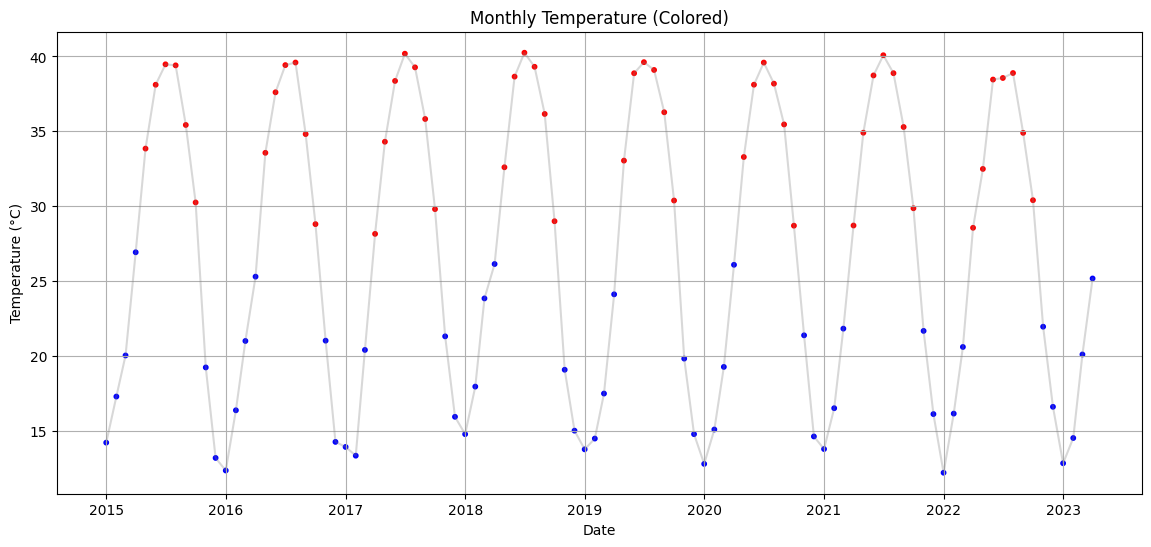

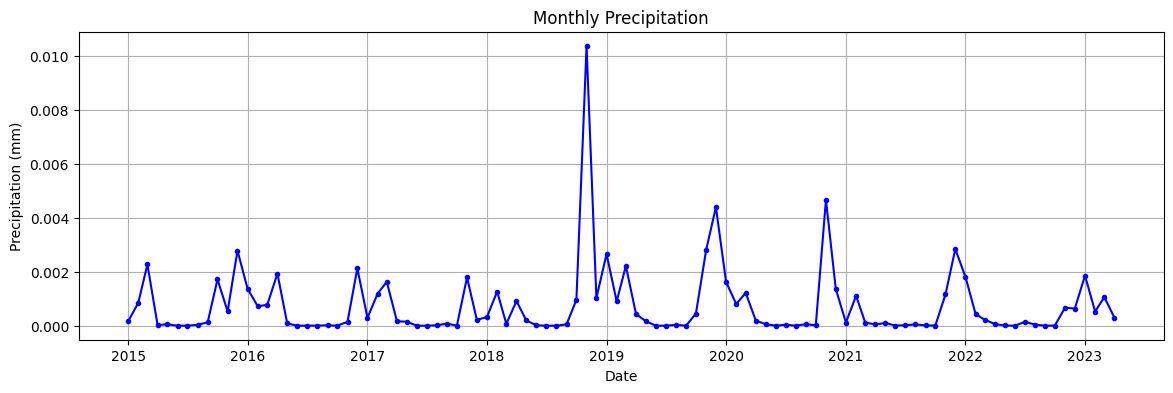

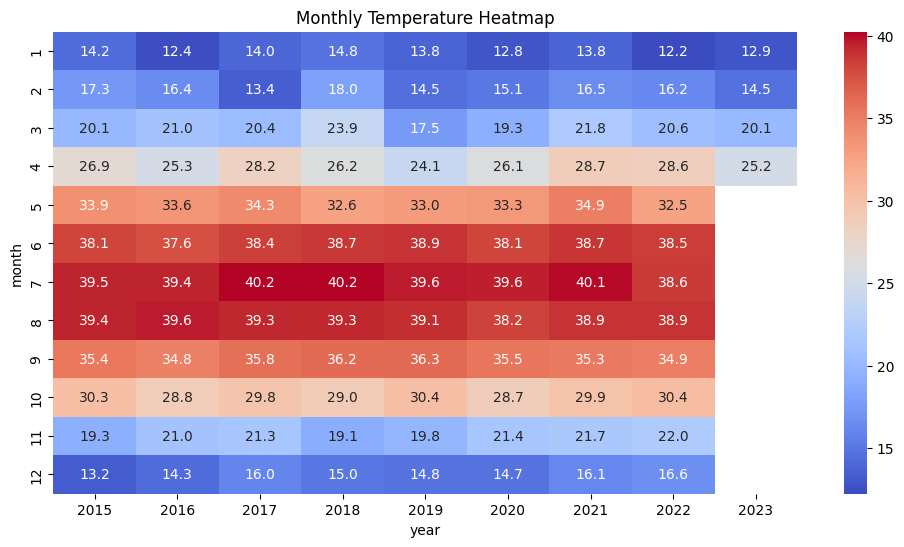

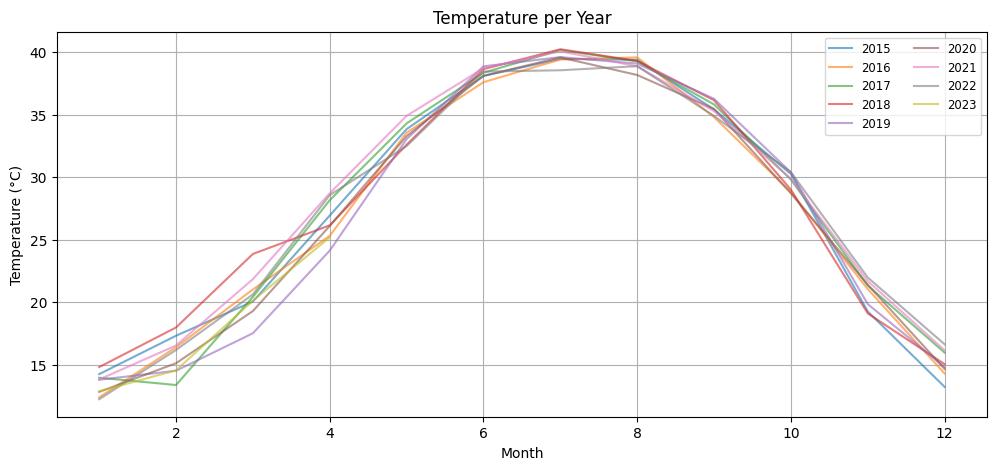

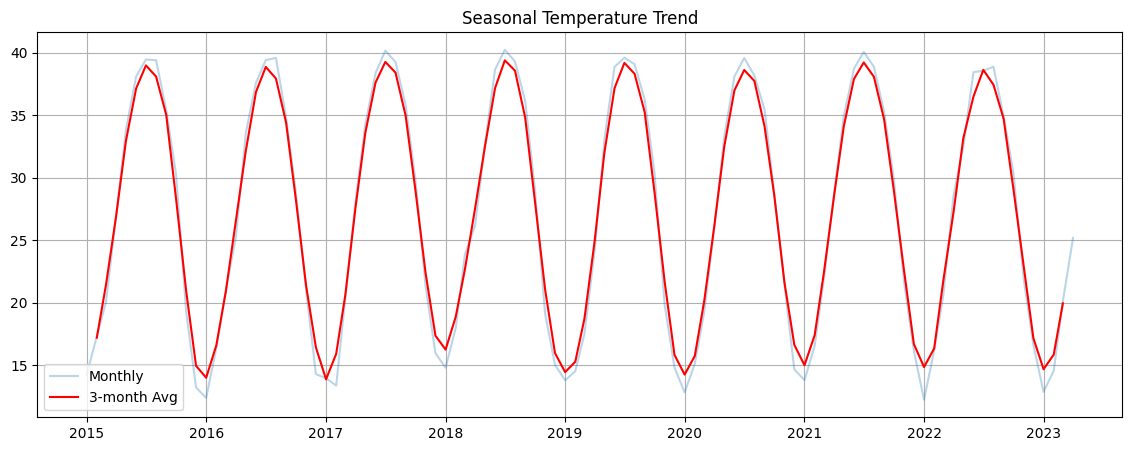

In [ ]:
import ee
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize Earth Engine
ee.Authenticate()
ee.Initialize(project='pars-460214')

# AOI definition
aoi = ee.FeatureCollection("projects/pars-460214/assets/dom")
aoi_geometry = aoi.geometry()

# Load ERA5 dataset
era5 = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY") \
    .filterDate("2015-01-01", "2025-12-31") \
    .select(['temperature_2m', 'total_precipitation'])

# Monthly mean reducer function
def compute_monthly_means(image):
    date = image.date().format('YYYY-MM')
    stats = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi_geometry,
        scale=10000,
        maxPixels=1e13
    )
    return ee.Feature(None, {
        'date': date,
        'temperature_2m': stats.get('temperature_2m'),
        'total_precipitation': stats.get('total_precipitation')
    })

monthly_features = era5.map(compute_monthly_means)
monthly_list = monthly_features.toList(monthly_features.size()).getInfo()
data = [f['properties'] for f in monthly_list]

# DataFrame setup
df = pd.DataFrame(data)
df['date'] = pd.to_datetime(df['date'])
df['temperature_celsius'] = df['temperature_2m'] - 273.15
df['precipitation_mm'] = df['total_precipitation']
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

# Save Excel output
df.to_excel("shadegan_era5_monthly.xlsx", index=False)

# ---------- Plotting ----------

# Plot 1: Colored line based on temperature
plt.figure(figsize=(14, 6))
colors = df['temperature_celsius'].apply(lambda t: 'red' if t > df['temperature_celsius'].mean() else 'blue')
plt.scatter(df['date'], df['temperature_celsius'], color=colors, s=10)
plt.plot(df['date'], df['temperature_celsius'], color='gray', alpha=0.3)
plt.title("Monthly Temperature (Colored)")
plt.ylabel("Temperature (°C)")
plt.xlabel("Date")
plt.grid(True)
plt.show()

# Plot 2: Precipitation
plt.figure(figsize=(14, 4))
plt.plot(df['date'], df['precipitation_mm'], color='blue', marker='o', markersize=3)
plt.title("Monthly Precipitation")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.grid(True)
plt.show()

# Plot 3: Heatmap
pivot_temp = df.pivot(index='month', columns='year', values='temperature_celsius')
plt.figure(figsize=(12, 6))
sns.heatmap(pivot_temp, cmap='coolwarm', annot=True, fmt=".1f")
plt.title("Monthly Temperature Heatmap")
plt.show()

# Plot 4: Line plot per year
plt.figure(figsize=(12, 5))
for year in sorted(df['year'].unique()):
    plt.plot(df[df['year'] == year]['month'], df[df['year'] == year]['temperature_celsius'], label=year, alpha=0.6)
plt.title("Temperature per Year")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.legend(ncol=2, fontsize="small")
plt.grid(True)
plt.show()

# Plot 5: Seasonal trend (3-month rolling average)
df_sorted = df.sort_values('date')
df_sorted['rolling_mean'] = df_sorted['temperature_celsius'].rolling(window=3, center=True).mean()
plt.figure(figsize=(14, 5))
plt.plot(df_sorted['date'], df_sorted['temperature_celsius'], alpha=0.3, label="Monthly")
plt.plot(df_sorted['date'], df_sorted['rolling_mean'], color="red", label="3-month Avg")
plt.title("Seasonal Temperature Trend")
plt.legend()
plt.grid(True)
plt.show()


این کد یک **اسکریپت پایتون** برای **دانلود، پردازش و بصری‌سازی داده‌های ماهانه دما و بارش** از مجموعه داده **ERA5-Land** در پلتفرم **Google Earth Engine (GEE)** است. هدف اصلی این اسکریپت، ایجاد تصاویر TIFF از نقشه‌های دما و بارش برای هر ماه در یک دوره زمانی مشخص، و سپس ترکیب این تصاویر به صورت مونتاژ (Montage) همراه با legend است.

---

## سال‌های مورد تحلیل

این اسکریپت داده‌های اقلیمی را برای یک دوره زمانی از **1 ژانویه 2015 تا 1 ژانویه 2025** استخراج و تحلیل می‌کند.

---

## فرمول‌های استفاده شده

در این اسکریپت، تبدیل واحدهای زیر برای داده‌های ERA5 انجام می‌شود:

* **تبدیل دما از کلوین به سلسیوس**:
    دمای ۲ متری (`temperature_2m`) از مجموعه داده ERA5 بر حسب **کلوین (K)** ارائه می‌شود. این اسکریپت آن را به **سلسیوس (°C)** تبدیل می‌کند.
    $$Temperature_{Celsius} = Temperature_{Kelvin} - 273.15$$

* **تبدیل بارش از متر به میلی‌متر**:
    بارش کلی (`total_precipitation`) از مجموعه داده ERA5 بر حسب **متر (m)** ارائه می‌شود. این اسکریپت آن را به **میلی‌متر (mm)** تبدیل می‌کند.
    $$Precipitation_{mm} = Total\_Precipitation_{m} \times 1000$$

---

## توابع اصلی

* `convert_units(img)`:
    * این تابع برای هر تصویر در مجموعه داده ERA5 فراخوانی می‌شود.
    * باند `temperature_2m` را از کلوین به سلسیوس تبدیل کرده و یک باند جدید به نام `temperature_celsius` ایجاد می‌کند.
    * باند `total_precipitation` را از متر به میلی‌متر تبدیل کرده و یک باند جدید به نام `precipitation_mm` ایجاد می‌کند.
    * تصویر حاصل را به همراه باندهای تبدیل شده و ویژگی‌های زمانی اصلی بازمی‌گرداند.

* `create_colorbar(filename, cmap, vmin, vmax, label)`:
    * یک نوار رنگی (colorbar) با استفاده از `matplotlib` ایجاد می‌کند.
    * این نوار رنگی به عنوان legend برای تصاویر دما و بارش استفاده می‌شود و به صورت یک فایل PNG ذخیره می‌شود (`temp_colorbar.png` و `precip_colorbar.png`).

* `create_montage_with_legend(image_files, output_path, legend_path)`:
    * لیستی از فایل‌های تصویری (TIFF) را می‌گیرد.
    * این تصاویر را به صورت یک **مونتاژ (Montage)** در یک تصویر بزرگتر ترکیب می‌کند.
    * عنوان تاریخ هر تصویر را به آن اضافه می‌کند.
    * نوار رنگی (legend) ایجاد شده قبلی را به پایین مونتاژ اضافه می‌کند.
    * تصویر مونتاژ نهایی را به صورت یک فایل JPEG ذخیره می‌کند.

---

## جریان اصلی برنامه

1.  **پیکربندی و راه‌اندازی Earth Engine**:
    * مسیرهای خروجی برای ذخیره تصاویر دما، بارش، GIFها و مونتاژها را تعریف می‌کند.
    * `ee.Initialize` را برای اتصال به Earth Engine انجام می‌دهد و در صورت نیاز، احراز هویت را آغاز می‌کند.
    * ناحیه مورد علاقه (AOI) را از یک FeatureCollection از پیش بارگذاری شده در Earth Engine دریافت می‌کند.

2.  **تنظیم پارامترهای بصری‌سازی**:
    * پارامترهای بصری‌سازی (`temp_vis_params` و `precip_vis_params`) شامل حداقل و حداکثر مقادیر و پالت‌های رنگی برای نمایش دما و بارش را تعریف می‌کند.

3.  **ایجاد نوارهای رنگی (Legends)**:
    * با استفاده از تابع `create_colorbar`، نوارهای رنگی برای دما و بارش ایجاد و ذخیره می‌کند.

4.  **دریافت و پردازش داده‌ها**:
    * مجموعه داده `ECMWF/ERA5_LAND/MONTHLY` را برای دوره زمانی و AOI مشخص فیلتر می‌کند.
    * تابع `convert_units` را بر روی هر تصویر در مجموعه اعمال می‌کند تا واحدها به سلسیوس و میلی‌متر تبدیل شوند.
    * تصاویر پردازش شده را به صورت جداگانه برای هر ماه در فرمت **TIFF** (که برای بصری‌سازی با پارامترهای رنگی قابل استفاده است) دانلود می‌کند. فایل‌های دما در `OUTPUT_TEMP_DIR` و فایل‌های بارش در `OUTPUT_PRECIP_DIR` ذخیره می‌شوند.

5.  **ایجاد مونتاژ تصاویر**:
    * پس از دانلود تمام تصاویر، از تابع `create_montage_with_legend` برای ترکیب تصاویر دما و بارش به صورت دو فایل مونتاژ جداگانه استفاده می‌کند.
    * **temperature_montage_with_legend.jpg**: مونتاژ تصاویر دما را به همراه نوار رنگی دما ایجاد می‌کند.
    * **precipitation_montage_with_legend.jpg**: مونتاژ تصاویر بارش را به همراه نوار رنگی بارش ایجاد می‌کند.
    * این فایل‌های مونتاژ در `OUTPUT_MONTAGE_DIR` ذخیره می‌شوند.

---

## خروجی‌ها

این اسکریپت چندین نوع خروجی تولید می‌کند که همگی در پوشه اصلی `era5_land_downloads` ذخیره می‌شوند:

* **فایل‌های تصویری TIFF (در پوشه‌های جداگانه)**:
    * **`era5_land_downloads/temperature/temp_YYYY_MM.tif`**: برای هر ماه یک فایل TIFF حاوی نقشه دمای ۲ متری (به سلسیوس) با رنگ‌آمیزی اعمال شده.
    * **`era5_land_downloads/precipitation/precip_YYYY_MM.tif`**: برای هر ماه یک فایل TIFF حاوی نقشه بارش کلی (به میلی‌متر) با رنگ‌آمیزی اعمال شده.

* **فایل‌های نوار رنگی (Legends)**:
    * **`temp_colorbar.png`**: نوار رنگی برای نمایش دما.
    * **`precip_colorbar.png`**: نوار رنگی برای نمایش بارش.

* **فایل‌های مونتاژ تصویری (در پوشه `montages`)**:
    * **`era5_land_downloads/montages/temperature_montage_with_legend.jpg`**: یک تصویر JPEG بزرگ که شامل تمام نقشه‌های دمای ماهانه (به صورت یک چیدمان شبکه‌ای) به همراه نوار رنگی دما و برچسب تاریخ هر ماه است.
    * **`era5_land_downloads/montages/precipitation_montage_with_legend.jpg`**: یک تصویر JPEG بزرگ که شامل تمام نقشه‌های بارش ماهانه (به صورت یک چیدمان شبکه‌ای) به همراه نوار رنگی بارش و برچسب تاریخ هر ماه است.

این اسکریپت با ارائه بصری‌سازی‌های ماهانه و یکپارچه از دما و بارش، به تحلیل تغییرات اقلیمی در منطقه تالاب شادگان در طول زمان کمک می‌کند.

In [ ]:
import ee
import geemap
import os
import glob
from PIL import Image, ImageDraw, ImageFont
import numpy as np
import matplotlib.pyplot as plt
import math

# --- Configuration ---
PROJECT_ID = 'pars-460214'
AOI_ASSET_ID = "projects/pars-460214/assets/dom"
START_DATE = '2015-01-01'
END_DATE = '2025-01-01'

OUTPUT_BASE_DIR = 'era5_land_downloads'
OUTPUT_TEMP_DIR = os.path.join(OUTPUT_BASE_DIR, 'temperature')
OUTPUT_PRECIP_DIR = os.path.join(OUTPUT_BASE_DIR, 'precipitation')
OUTPUT_GIF_DIR = os.path.join(OUTPUT_BASE_DIR, 'gifs')
OUTPUT_MONTAGE_DIR = os.path.join(OUTPUT_BASE_DIR, 'montages')
os.makedirs(OUTPUT_TEMP_DIR, exist_ok=True)
os.makedirs(OUTPUT_PRECIP_DIR, exist_ok=True)
os.makedirs(OUTPUT_GIF_DIR, exist_ok=True)
os.makedirs(OUTPUT_MONTAGE_DIR, exist_ok=True)

try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)

aoi = ee.FeatureCollection(AOI_ASSET_ID)
aoi_geometry = aoi.union().geometry()

# Convert units

def convert_units(img):
    temp_c = img.select('temperature_2m').subtract(273.15).rename('temperature_celsius')
    precip_mm = img.select('total_precipitation').multiply(1000).rename('precipitation_mm')
    return img.addBands(temp_c).addBands(precip_mm).copyProperties(img, ['system:time_start'])

# Visualization parameters
temp_vis_params = {
    'min': -10, 'max': 40,
    'palette': ['blue', 'cyan', 'limegreen', 'yellow', 'orange', 'red']
}

precip_vis_params = {
    'min': 0, 'max': 100,
    'palette': ['lightblue', 'deepskyblue', 'blue', 'darkblue', 'purple']
}

# Create legend bar for visualization

def create_colorbar(filename, cmap, vmin, vmax, label):
    fig, ax = plt.subplots(figsize=(6, 1))
    fig.subplots_adjust(bottom=0.5)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=ax, orientation='horizontal', label=label)
    plt.savefig(filename, bbox_inches='tight')
    plt.close()

create_colorbar('temp_colorbar.png', plt.cm.get_cmap('RdYlBu_r'), -10, 40, 'Temperature (°C)')
create_colorbar('precip_colorbar.png', plt.cm.get_cmap('Purples'), 0, 100, 'Precipitation (mm)')

# Data acquisition
era5_collection = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY") \
    .filterDate(START_DATE, END_DATE) \
    .filterBounds(aoi_geometry) \
    .select(['temperature_2m', 'total_precipitation']) \
    .map(convert_units) \
    .select(['temperature_celsius', 'precipitation_mm'])

collection_size = era5_collection.size().getInfo()
downloaded_temp_files = []
downloaded_precip_files = []

for i in range(collection_size):
    image = ee.Image(era5_collection.toList(collection_size).get(i))
    date_str = ee.Date(image.get('system:time_start')).format('YYYY_MM').getInfo()

    temp_filename = os.path.join(OUTPUT_TEMP_DIR, f"temp_{date_str}.tif")
    if not os.path.exists(temp_filename):
        vis_temp_image = image.select('temperature_celsius').visualize(**temp_vis_params)
        geemap.ee_export_image(vis_temp_image, filename=temp_filename, scale=300, region=aoi_geometry, file_per_band=False)
    downloaded_temp_files.append(temp_filename)

    precip_filename = os.path.join(OUTPUT_PRECIP_DIR, f"precip_{date_str}.tif")
    if not os.path.exists(precip_filename):
        vis_precip_image = image.select('precipitation_mm').visualize(**precip_vis_params)
        geemap.ee_export_image(vis_precip_image, filename=precip_filename, scale=300, region=aoi_geometry, file_per_band=False)
    downloaded_precip_files.append(precip_filename)

# Create montage with legend and label

def create_montage_with_legend(image_files, output_path, legend_path):
    image_files.sort()
    images = [Image.open(f) for f in image_files if os.path.exists(f)]
    if not images:
        return

    img_width, img_height = images[0].size
    columns = min(5, len(images))
    rows = math.ceil(len(images) / columns)
    padding = 10
    text_height = 30
    legend_height = 60
    width = columns * img_width + (columns + 1) * padding
    height = rows * (img_height + text_height) + (rows + 1) * padding + legend_height
    montage = Image.new('RGB', (width, height), 'white')
    draw = ImageDraw.Draw(montage)

    try:
        font = ImageFont.truetype("arial.ttf", 20)
    except:
        font = ImageFont.load_default()

    for idx, img in enumerate(images):
        row, col = divmod(idx, columns)
        x = padding + col * (img_width + padding)
        y = padding + row * (img_height + text_height + padding)
        montage.paste(img, (x, y))

        filename = os.path.basename(image_files[idx])
        date = "_".join(filename.split('_')[1:]).split('.')[0]
        draw.text((x + img_width // 2 - 30, y + img_height + 5), date, font=font, fill='black')

    if os.path.exists(legend_path):
        legend = Image.open(legend_path)
        legend = legend.resize((width - 2 * padding, legend_height - padding))
        montage.paste(legend, (padding, height - legend_height))

    montage.save(output_path)

create_montage_with_legend(downloaded_temp_files, os.path.join(OUTPUT_MONTAGE_DIR, 'temperature_montage_with_legend.jpg'), 'temp_colorbar.png')
create_montage_with_legend(downloaded_precip_files, os.path.join(OUTPUT_MONTAGE_DIR, 'precipitation_montage_with_legend.jpg'), 'precip_colorbar.png')


Generating URL ...
Please wait ...
Data downloaded to /content/era5_land_downloads/temperature/temp_2015_01.tif
Generating URL ...
Please wait ...
Data downloaded to /content/era5_land_downloads/precipitation/precip_2015_01.tif
Generating URL ...
Please wait ...
Data downloaded to /content/era5_land_downloads/temperature/temp_2015_02.tif
Generating URL ...
Please wait ...
Data downloaded to /content/era5_land_downloads/precipitation/precip_2015_02.tif
Generating URL ...
Please wait ...
Data downloaded to /content/era5_land_downloads/temperature/temp_2015_03.tif
Generating URL ...
Please wait ...
Data downloaded to /content/era5_land_downloads/precipitation/precip_2015_03.tif
Generating URL ...
Please wait ...
Data downloaded to /content/era5_land_downloads/temperature/temp_2015_04.tif
Generating URL ...
Please wait ...
Data downloaded to /content/era5_land_downloads/precipitation/precip_2015_04.tif
Generating URL ...
Please wait ...
Data downloaded to /content/era5_land_downloads/tempe

این کد یک **اسکریپت پایتون** برای **تعیین مناطق اولویت‌دار برای احیا در تالاب شادگان** با استفاده از داده‌های ماهواره‌ای و اقلیمی از **Google Earth Engine (GEE)** است. این اسکریپت با ترکیب چندین لایه اطلاعاتی مانند شاخص‌های پوشش گیاهی، آب، کدورت، ارتفاع، دما و بارش، مناطقی با اولویت بالا، متوسط و پایین برای احیا را شناسایی می‌کند.

---

## سال‌های مورد تحلیل

این اسکریپت از داده‌های مربوط به **ماه جولای (ماه 7)** از سال‌های **2015 تا 2024** برای داده‌های ماهواره‌ای لندست (Landsat) و داده‌های اقلیمی ERA5 استفاده می‌کند. نقشه پوشش اراضی ESA WorldCover مربوط به سال 2020 است.

---

## فرمول‌های استفاده شده

این اسکریپت از چندین شاخص ماهواره‌ای و تبدیل واحد استفاده می‌کند:

* **نرمال‌سازی باندهای اپتیکی Landsat**:
    باندهای اپتیکی (SR\_B1 تا SR\_B7) تصاویر لندست از مقیاس 16 بیتی به مقادیر رفلکتانس سطح (Surface Reflectance) تبدیل می‌شوند:
    $$Reflectance = (Digital\ Number \times 0.0000275) - 0.2$$

* **شاخص نرمال شده پوشش گیاهی (NDVI - Normalized Difference Vegetation Index)**:
    برای ارزیابی سلامت و تراکم پوشش گیاهی استفاده می‌شود.
    $$NDVI = \frac{(NIR - Red)}{(NIR + Red)}$$
    که در آن:
    * **NIR**: باند فروسرخ نزدیک (SR\_B5 در لندست 8)
    * **Red**: باند قرمز (SR\_B4 در لندست 8)

* **شاخص نرمال شده آب (NDWI - Normalized Difference Water Index)**:
    برای شناسایی و نقشه‌برداری از پهنه‌های آبی استفاده می‌شود.
    $$NDWI = \frac{(Green - NIR)}{(Green + NIR)}$$
    که در آن:
    * **Green**: باند سبز (SR\_B3 در لندست 8)
    * **NIR**: باند فروسرخ نزدیک (SR\_B5 در لندست 8)

* **کدورت (Turbidity)**:
    از باند آبی (SR\_B2) به عنوان یک نماینده اولیه برای کدورت آب استفاده می‌شود. مقادیر بالاتر باند آبی معمولاً با کدورت بیشتر آب ارتباط دارد.
    $$Turbidity \approx Blue\ Band\ (SR\_B2)$$

* **روند NDVI (NDVI Trend)**:
    این شاخص تغییرات NDVI را در طول زمان (از سال 2015) برای هر پیکسل مدل‌سازی می‌کند تا مناطق با کاهش یا افزایش پوشش گیاهی را شناسایی کند. از یک رگرسیون خطی ساده استفاده می‌شود که شیب (`scale`) خط روند را به عنوان `NDVI_trend` در نظر می‌گیرد.

* **تبدیل دما از کلوین به سلسیوس**:
    دمای ۲ متری (`temperature_2m`) از ERA5 به **سلسیوس (°C)** تبدیل می‌شود.
    $$Temperature_{Celsius} = Temperature_{Kelvin} - 273.15$$

* **تبدیل بارش از متر به میلی‌متر**:
    بارش کلی (`total_precipitation`) از ERA5 به **میلی‌متر (mm)** تبدیل می‌شود.
    $$Precipitation_{mm} = Total\_Precipitation_{m} \times 1000$$

* **نرمال‌سازی (Normalization)**:
    تمام باندهای ورودی (NDVI, NDWI, Turbidity, Temperature, Precipitation, DEM, NDVI\_trend) به مقیاس 0 تا 1 نرمال می‌شوند. برای شاخص‌هایی مانند NDVI, NDWI, DEM, Precipitation و NDVI\_trend که مقادیر بالاترشان نشان‌دهنده شرایط بهتر (یا مطلوب‌تر برای احیا) است، نرمال‌سازی به صورت معکوس انجام می‌شود تا مقادیر کمتر در خروجی نرمال‌شده نشان‌دهنده شرایط مطلوب‌تر باشند.
    $$Normalized\ Value = \frac{(Raw\ Value - Min\ Value)}{(Max\ Value - Min\ Value)}$$
    و برای موارد معکوس:
    $$Normalized\ Value = 1 - \frac{(Raw\ Value - Min\ Value)}{(Max\ Value - Min\ Value)}$$

---

## توابع و مراحل اصلی

1.  **آماده‌سازی تصاویر لندست (Landsat Image Preparation)**:
    * مجموعه تصاویر Landsat 8 را برای ناحیه مورد نظر، بین سال‌های 2015 تا 2025 و فقط برای ماه جولای فیلتر می‌کند.
    * تصاویر با پوشش ابر کمتر از 5% انتخاب می‌شوند.
    * تابع `process_image` را بر روی هر تصویر اعمال می‌کند تا باندهای اپتیکی را نرمال‌سازی کرده و شاخص‌های **NDVI، NDWI و Turbidity (کدورت)** را محاسبه کند.
    * یک تصویر ترکیبی مدیان (Median Composite) از تمام تصاویر پردازش شده ایجاد می‌کند.

2.  **داده‌های اقلیمی ERA5 (ERA5 Climate Data)**:
    * داده‌های ماهانه `ERA5-Land Monthly` را برای ناحیه مورد نظر و ماه جولای (بین 2015 تا 2025) فیلتر می‌کند.
    * میانگین دمای ۲ متری و میانگین بارش کلی را در این دوره زمانی محاسبه کرده و واحدها را به سلسیوس و میلی‌متر تبدیل می‌کند.

3.  **مدل ارتفاعی رقومی (DEM) و پوشش اراضی (Landcover)**:
    * مدل ارتفاعی رقومی SRTM (با نام `DEM`) و نقشه پوشش اراضی جهانی ESA WorldCover 2020 (با نام `LandCover`) را برای AOI بارگذاری می‌کند.

4.  **روند NDVI (NDVI Trend)**:
    * یک باند زمانی (`x`) و باند NDVI (`y`) برای هر تصویر Landsat ایجاد می‌کند.
    * رگرسیون خطی را بر روی این باندها برای هر پیکسل اجرا می‌کند تا شیب (`scale`) روند NDVI را در طول زمان (از 2015 تا 2024) محاسبه کند. این شیب به عنوان `NDVI_trend` ذخیره می‌شود.

5.  **نرمال‌سازی ورودی‌ها (Normalize Inputs)**:
    * تمام باندهای محاسبه شده (`NDVI`, `NDWI`, `Turbidity`, `Temperature`, `Precipitation`, `DEM`, `NDVI_trend`) را به مقیاس 0 تا 1 نرمال می‌کند. برای برخی از شاخص‌ها، نرمال‌سازی معکوس اعمال می‌شود (توضیح در بخش فرمول‌ها).

6.  **تعریف قوانین ریسک/اولویت (Risk Rules)**:
    * مناطق با اولویت بالا، متوسط و پایین برای احیا بر اساس ترکیب منطقی آستانه‌هایی از شاخص‌های نرمال‌شده و کلاس‌های پوشش اراضی تعریف می‌شوند:
        * **High Priority (اولویت بالا)**: مناطقی که NDVI و NDWI پایینی دارند (کمبود پوشش گیاهی و آب)، یا مناطقی با پوشش اراضی شهری (کد 50) یا تالاب‌های تخریب‌شده/خشک‌شده (کد 100)، یا مناطقی که `NDVI_trend` بالایی دارند (کاهش شدید NDVI)، یا `Turbidity` بالایی دارند.
        * **Low Priority (اولویت پایین)**: مناطقی که NDVI و NDWI بالایی دارند (پوشش گیاهی و آب سالم)، یا مناطقی با پوشش اراضی آبی (کد 10) یا جنگلی/شاخ و برگ (کد 70)، یا `Turbidity` پایینی دارند.
        * **Medium Priority (اولویت متوسط)**: مناطقی که نه در دسته "اولویت بالا" و نه در دسته "اولویت پایین" قرار می‌گیرند.

7.  **تولید داده‌های آموزشی (Generate Training Data)**:
    * نمونه‌های پیکسلی را برای هر یک از کلاس‌های اولویت (بالا، متوسط، پایین) از روی تصویر `features` (که شامل تمام باندهای نرمال شده است) استخراج می‌کند. این نمونه‌ها برای آموزش طبقه‌بند استفاده می‌شوند.

8.  **طبقه‌بندی و پس‌پردازش (Classify & Post-process)**:
    * یک طبقه‌بند **Random Forest** (با 50 درخت) با استفاده از داده‌های آموزشی، آموزش داده می‌شود.
    * تصویر `features` با استفاده از این طبقه‌بند، به نقشه‌ای از کلاس‌های اولویت (1: بالا، 2: متوسط، 3: پایین) طبقه‌بندی می‌شود.
    * فیلتر `focal_median` با شعاع 2 پیکسل برای صاف کردن نتایج طبقه‌بندی و حذف نویز اعمال می‌شود.
    * تصویر نهایی به AOI برش داده می‌شود.

9.  **بصری‌سازی (Visualization)**:
    * نقشه طبقه‌بندی شده `Restoration Priority` به `geemap.Map` اضافه می‌شود.
    * یک Legend (مقیاس رنگ) با برچسب‌های `High Priority` (قرمز), `Medium Priority` (نارنجی) و `Low Priority` (سبز) به نقشه اضافه می‌شود.

10. **خروجی به Google Drive (Export to Drive)**:
    * تصویر نهایی طبقه‌بندی شده و صاف شده (`smoothed`) به صورت یک فایل GeoTIFF به پوشه `GEE_exports` در Google Drive کاربر صادر می‌شود.

---

## خروجی‌ها

* **نمایش تعاملی نقشه**:
    * یک نقشه تعاملی `geemap` که لایه `Restoration Priority` را نمایش می‌دهد، در محیط اجرا قابل مشاهده است. این نقشه مناطق با اولویت بالا (قرمز)، متوسط (نارنجی) و پایین (سبز) را برای احیا در تالاب شادگان نشان می‌دهد.
    * Legend (مقیاس رنگ) مربوط به کلاس‌های اولویت نیز بر روی نقشه نمایش داده می‌شود.

* **فایل GeoTIFF به Google Drive**:
    * یک فایل GeoTIFF با نام `Restoration_Priority_Shadegan_Final.tif` به پوشه `GEE_exports` در Google Drive شما صادر می‌شود. این فایل شامل مقادیر 1، 2 و 3 برای کلاس‌های اولویت احیا است که برای تحلیل‌های مکانی بیشتر در نرم‌افزارهای GIS قابل استفاده است.

این اسکریپت با تلفیق داده‌های متنوع، یک ابزار ارزشمند برای تصمیم‌گیری‌های مبتنی بر شواهد در زمینه مدیریت و احیای تالاب شادگان فراهم می‌کند.

In [ ]:
import ee
import geemap
ee.Authenticate()
ee.Initialize(project='pars-460214')
# منطقه مورد نظر
aoi = ee.FeatureCollection('projects/pars-460214/assets/dom')
aoi_geometry = aoi.geometry()



# Prepare Landsat Image
landsat = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
           .filterBounds(aoi_geometry)
           .filterDate('2015-01-01', '2025-01-01')
           .filter(ee.Filter.calendarRange(7, 7, 'month'))
           .filter(ee.Filter.lt('CLOUD_COVER', 5)))

def process_image(image):
    optical = image.select(['SR_B1','SR_B2','SR_B3','SR_B4','SR_B5','SR_B6','SR_B7']).multiply(0.0000275).add(-0.2)
    ndvi = optical.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI')
    ndwi = optical.normalizedDifference(['SR_B3', 'SR_B5']).rename('NDWI')
    turbidity = optical.select('SR_B2').rename('Turbidity')
    return image.addBands(optical).addBands(ndvi).addBands(ndwi).addBands(turbidity)

landsat = landsat.map(process_image)
composite = landsat.median().clip(aoi_geometry)

# ERA5 climate data
era5 = (ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY")
        .filterDate('2015-01-01', '2025-01-01')
        .filterBounds(aoi_geometry)
        .filter(ee.Filter.calendarRange(7, 7, 'month')))

temperature = era5.select('temperature_2m').mean().subtract(273.15).rename('Temperature').clip(aoi_geometry)
precipitation = era5.select('total_precipitation').mean().multiply(1000).rename('Precipitation').clip(aoi_geometry)

# DEM & Landcover
dem = ee.Image('USGS/SRTMGL1_003').select('elevation').rename('DEM').clip(aoi_geometry)
landcover = ee.Image('ESA/WorldCover/v100/2020').select('Map').rename('LandCover').clip(aoi_geometry)

# NDVI Trend
def ndvi_trend_func(image):
    ndvi = image.select('NDVI').rename('y')
    timeBand = ee.Image.constant(image.date().get('year')).subtract(2015).toFloat().rename('x')
    return timeBand.addBands(ndvi)

ndvi_trend = landsat.map(ndvi_trend_func).reduce(ee.Reducer.linearFit()).select('scale').rename('NDVI_trend')

# Normalize function
def normalize(image, band):
    minmax = image.reduceRegion(ee.Reducer.minMax(), aoi_geometry, 250, bestEffort=True)
    min_val = ee.Number(minmax.get(band + "_min"))
    max_val = ee.Number(minmax.get(band + "_max"))
    raw = image.select(band)
    if band in ['NDVI', 'NDWI', 'DEM', 'Precipitation', 'NDVI_trend']:
        norm = raw.subtract(min_val).divide(max_val.subtract(min_val)).multiply(-1).add(1)
    else:
        norm = raw.subtract(min_val).divide(max_val.subtract(min_val))
    return norm.rename(band + "_norm")

# Normalize inputs
ndvi_norm = normalize(composite, 'NDVI')
ndwi_norm = normalize(composite, 'NDWI')
turbidity_norm = normalize(composite, 'Turbidity')
temp_norm = normalize(temperature, 'Temperature')
precip_norm = normalize(precipitation, 'Precipitation')
dem_norm = normalize(dem, 'DEM')
ndvi_trend_norm = normalize(ndvi_trend, 'NDVI_trend')

features = ndvi_norm.addBands([ndwi_norm, turbidity_norm, temp_norm,
                               precip_norm, dem_norm, ndvi_trend_norm, landcover])
feature_names = features.bandNames()

# Risk rules
high = (ndvi_norm.lt(0.53).And(ndwi_norm.lt(0.53))
        .Or(landcover.eq(50))
        .Or(landcover.eq(100))
        .Or(ndvi_trend_norm.gt(0.45))
        .Or(turbidity_norm.gt(0.6)))

low = (ndvi_norm.gt(0.55).And(ndwi_norm.gt(0.55))
       .Or(landcover.eq(10))
       .Or(landcover.eq(70))
       .Or(turbidity_norm.lt(0.35)))

medium = high.Not().And(low.Not())

# Generate training data
def sample_class(mask, label):
    return features.updateMask(mask).sample(
        region=aoi_geometry, scale=250, numPixels=5000, seed=0
    ).map(lambda f: f.set('class', label))

training_data = (sample_class(high, 1)
                 .merge(sample_class(medium, 2))
                 .merge(sample_class(low, 3)))

classifier = ee.Classifier.smileRandomForest(50).train(
    features=training_data, classProperty='class', inputProperties=feature_names
)

# Classify & post-process
classified = features.classify(classifier).rename('PriorityClass')
smoothed = classified.focal_median(radius=2, units='pixels').clip(aoi_geometry)

# --- Visualization ---

vis_params = {
    'min': 1,
    'max': 3,
    'palette': ['red', 'orange', 'green']
}

# Define the map and add the classified layer
Map = geemap.Map(center=[30.65, 48.65], zoom=9)
Map.addLayer(smoothed, vis_params, 'Restoration Priority')

# اضافه کردن لِجِند به روش بدون ارور
keys = ['High Priority', 'Medium Priority', 'Low Priority']
# Convert color names to RGB tuples
colors = [(255, 0, 0), (255, 165, 0), (0, 128, 0)] # RGB for Red, Orange, Green
Map.add_legend(title='Restoration Priority', keys=keys, colors=colors)

Map


# --- Export to Drive ---
export_task = ee.batch.Export.image.toDrive(
    image=smoothed,
    description='Restoration_Priority_Shadegan_Final',
    folder='GEE_exports',
    fileNamePrefix='Restoration_Priority_Shadegan_Final',
    region=aoi_geometry,
    scale=250,
    maxPixels=1e13
)
export_task.start()

print('✅ Export started! Check your Google Drive folder "GEE_exports".')


✅ Export started! Check your Google Drive folder "GEE_exports".
